# **Concrete Compressive Strength Prediction**

## **Project Aim**

The primary aim of this project is to develop and evaluate supervised Machine Learning regression models for predicting the compressive strength of concrete. The project will analyse concrete mixture components and curing age, preprocess the dataset, explore relationships between the variables, and compare suitable regression algorithms to identify the most effective model for predicting concrete compressive strength in MPa.

## **Problem Statement**







The accurate estimation of concrete compressive strength is crucial for ensuring structural safety, construction quality, and efficient use of materials. However, determining compressive strength through traditional laboratory testing can be time-consuming, costly, and dependent on curing periods. Concrete strength is also influenced by several factors, including cement content, water, aggregates, admixtures, and age. This project addresses the challenge of developing reliable machine learning models that can accurately predict concrete compressive strength based on these mixture and curing-related factors, thereby providing useful insights for engineers and construction professionals to support material design, quality assessment, and decision-making.


## **Dataset Overview**


## **Column Descriptions**

### **Independent Variables**
- `Cement (component 1)(kg in a m^3 mixture):` Amount of cement used in the concrete mixture, measured in kilograms per cubic meter.
- `Blast Furnace Slag (component 2)(kg in a m^3 mixture):` Amount of blast furnace slag used as a supplementary cementitious material in the concrete mixture, measured in kilograms per cubic meter.
- `Fly Ash (component 3)(kg in a m^3 mixture):` Amount of fly ash used as a supplementary cementitious material in the concrete mixture, measured in kilograms per cubic meter.
- `Water  (component 4)(kg in a m^3 mixture):` Amount of water used in the concrete mixture, measured in kilograms per cubic meter.
- `Superplasticizer (component 5)(kg in a m^3 mixture):` Amount of superplasticizer added to improve the workability of the concrete mixture, measured in kilograms per cubic meter.
- `Coarse Aggregate  (component 6)(kg in a m^3 mixture):` Amount of coarse aggregate used in the concrete mixture, measured in kilograms per cubic meter.
- `Fine Aggregate (component 7)(kg in a m^3 mixture):` Amount of fine aggregate used in the concrete mixture, measured in kilograms per cubic meter.
- `Age (day):` Number of days the concrete specimen has been cured before its compressive strength is measured.


### **Dependent Variable**
- `Concrete compressive strength(MPa, megapascals):` Compressive strength of the concrete specimen measured in megapascals (MPa).

In [2]:
# Importing the Required Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [3]:
from pathlib import Path

# Loading datasets
data_path = Path.cwd().parent / "data" / "Concrete_Compressive_Strength.csv"
concrete_data = pd.read_csv(data_path)

## **Assessment of Datasets**

In [4]:
concrete_data.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [5]:
concrete_data.sample(5)

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
622,307.0,0.0,0.0,193.0,0.0,968.0,812.0,365,36.15
848,252.0,97.0,76.0,194.0,8.0,835.0,821.0,28,33.40
548,289.0,0.0,0.0,192.0,0.0,913.2,895.3,28,25.57
881,153.0,145.0,113.0,178.0,8.0,1002.0,689.0,28,25.56
209,230.0,0.0,118.3,195.5,4.6,1029.4,758.6,3,10.03


In [6]:
concrete_data.tail()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.70
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.77
1029,260.9,100.5,78.3,200.6,8.6,864.5,761.5,28,32.40


In [7]:
concrete_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)        1030 

In [8]:
# Checking Missing Values
concrete_data.isnull().sum()

Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64

In [9]:
# Checking duplicate rows
concrete_data.duplicated().sum()

np.int64(25)

In [10]:
# Descriptive Statistics
concrete_data.describe()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


## **Summary of Datasets**

This dataset contains 1,030 concrete mixture records, combining information about the materials used in concrete production with the resulting compressive strength. For each concrete sample, it records the amount of cement, blast furnace slag, fly ash, water, superplasticizer, coarse aggregate, and fine aggregate used in the mixture. It also includes the age of the concrete in days, which represents the curing period before strength measurement. The target variable is concrete compressive strength, measured in megapascals (MPa). Overall, the dataset is well-suited for exploring relationships between concrete mixture components and strength, analyzing how curing age affects concrete performance, identifying important factors that influence strength, and developing machine learning regression models to accurately predict concrete compressive strength.



## **Messy Data Issues**

- Some column names contain spaces, special characters, and units in brackets, such as `Cement (kg in a m^3 mixture)` and `Concrete compressive strength (MPa, megapascals)`. Although these column names are not incorrect, they are inconvenient for coding, data preprocessing, and machine learning pipelines. Therefore, the columns were renamed using a consistent snake_case format, such as `cement`, `blast_furnace_slag`, `fly_ash, water`, `superplasticizer`, `coarse_aggregate`, `fine_aggregate`, `age`, and `concrete_compressive_strength`.

- The column name `'Concrete compressive strength(MPa, megapascals) '` has extra hidden space at the end.



## **Dirty Data Issues**

- The dataset also contained 25 duplicate records. Duplicate observations can unnecessarily repeat the same information and may influence the training process. Therefore, these duplicate rows were identified and removed leaving only unique records for further analysis and model development.

## **Data Cleaning**

In [11]:
# Check if columns contains an extra hidden space at the end
for column in concrete_data.columns:
    print(repr(column))

'Cement (component 1)(kg in a m^3 mixture)'
'Blast Furnace Slag (component 2)(kg in a m^3 mixture)'
'Fly Ash (component 3)(kg in a m^3 mixture)'
'Water  (component 4)(kg in a m^3 mixture)'
'Superplasticizer (component 5)(kg in a m^3 mixture)'
'Coarse Aggregate  (component 6)(kg in a m^3 mixture)'
'Fine Aggregate (component 7)(kg in a m^3 mixture)'
'Age (day)'
'Concrete compressive strength(MPa, megapascals) '


In [12]:
# Create a copy of the original dataset
concrete_data_df = concrete_data.copy()

# Remove leading and trailing spaces from column names
concrete_data_df.columns = concrete_data_df.columns.str.strip()

# Cleaning messy column names
rename_map = {
    "Cement (component 1)(kg in a m^3 mixture)": "cement",
    "Blast Furnace Slag (component 2)(kg in a m^3 mixture)": "blast_furnace_slag",
    "Fly Ash (component 3)(kg in a m^3 mixture)": "fly_ash",
    "Water  (component 4)(kg in a m^3 mixture)": "water",
    "Superplasticizer (component 5)(kg in a m^3 mixture)": "superplasticizer",
    "Coarse Aggregate  (component 6)(kg in a m^3 mixture)": "coarse_aggregate",
    "Fine Aggregate (component 7)(kg in a m^3 mixture)": "fine_aggregate",
    "Age (day)": "age",
    "Concrete compressive strength(MPa, megapascals)": "concrete_compressive_strength"
}

# Rename the columns
concrete_data_df = concrete_data_df.rename(columns=rename_map)

In [13]:
# Remove duplicate values
concrete_data_df = concrete_data_df.drop_duplicates()

In [14]:
concrete_data_df.duplicated().sum()

np.int64(0)

In [15]:
print("Before removing duplicates:", concrete_data.shape)
print("After removing duplicates:", concrete_data_df.shape)

Before removing duplicates: (1030, 9)
After removing duplicates: (1005, 9)


In [16]:
# Checking the cleaned data
concrete_data_df.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## **EDA (Exploratory Data Analysis)**

### **Column Types**

**Target (Numerical):**
- `concrete_compressive_strength`

**Numerical Features:**
- `cement`, `blast_furnace_slag`, `fly_ash`, `water`, `superplasticizer`, `coarse_aggregate`, `fine_aggregate`, `age`



## **Univariate Analysis on Numerical Features**

In [17]:
def univariate_analysis(df, column, bins=20):
    """
    Perform univariate analysis on a numerical column.
    Displays summary stats, histogram, KDE, box plot, and skewness.
    """
    print(f"{'='*50}")
    print(f"Analysis for: {column}")
    print(f"{'='*50}\n")

    # Summary statistics
    print("Summary Statistics:")
    print(df[column].describe())
    print(f"\nSkewness: {df[column].skew():.3f}\n")

    # Create subplots
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    # Histogram
    df[column].plot(kind='hist', bins=bins, ax=axes[0], edgecolor='black')
    axes[0].set_xlabel(column)
    axes[0].set_ylabel('Frequency')
    axes[0].set_title(f'Histogram of {column}')

    # KDE Plot
    df[column].plot(kind='kde', ax=axes[1])
    axes[1].set_xlabel(column)
    axes[1].set_ylabel('Density')
    axes[1].set_title(f'KDE of {column}')

    # Box Plot
    df[column].plot(kind='box', ax=axes[2])
    axes[2].set_xticklabels([column])
    axes[2].set_ylabel('Value')
    axes[2].set_title(f'Box Plot of {column}')

    plt.tight_layout()
    plt.show()



## **1. `cement`**

Analysis for: cement

Summary Statistics:
count    1005.000000
mean      278.631343
std       104.344261
min       102.000000
25%       190.700000
50%       265.000000
75%       349.000000
max       540.000000
Name: cement, dtype: float64

Skewness: 0.565



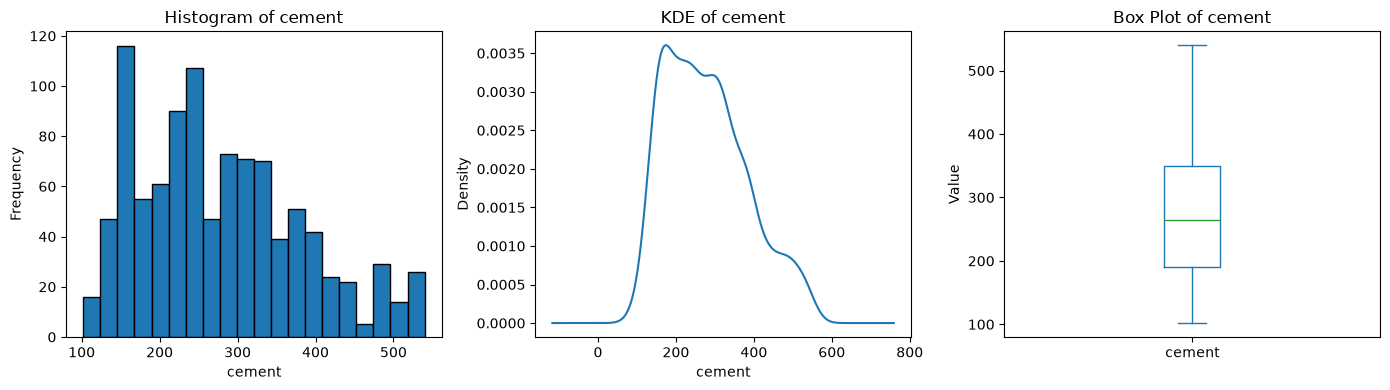

In [18]:
univariate_analysis(concrete_data_df, 'cement')

## **2. `blast_furnace_slag`**

Analysis for: blast_furnace_slag

Summary Statistics:
count    1005.000000
mean       72.043483
std        86.170807
min         0.000000
25%         0.000000
50%        20.000000
75%       142.500000
max       359.400000
Name: blast_furnace_slag, dtype: float64

Skewness: 0.855



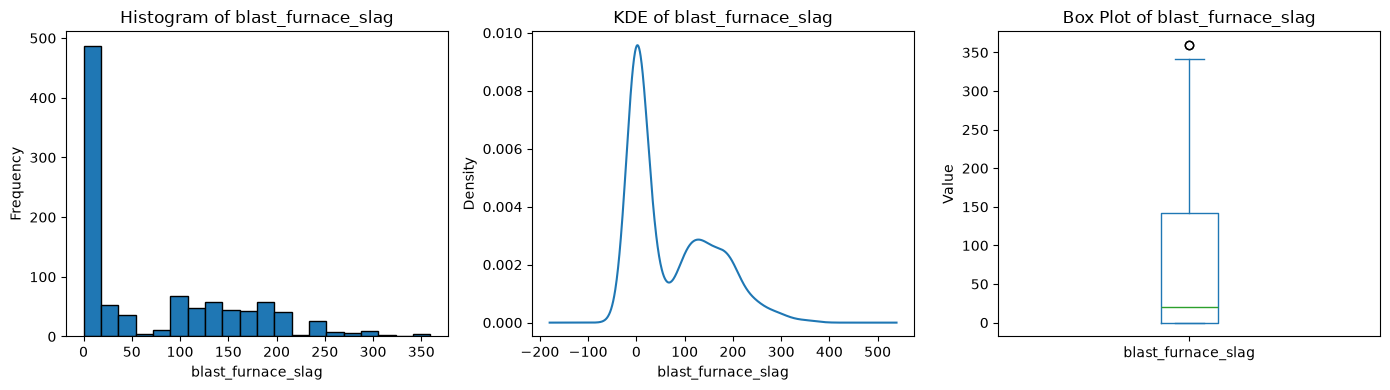

In [19]:
univariate_analysis(concrete_data_df, 'blast_furnace_slag')

## **3. `fly_ash`**

Analysis for: fly_ash

Summary Statistics:
count    1005.000000
mean       55.536318
std        64.207969
min         0.000000
25%         0.000000
50%         0.000000
75%       118.300000
max       200.100000
Name: fly_ash, dtype: float64

Skewness: 0.497



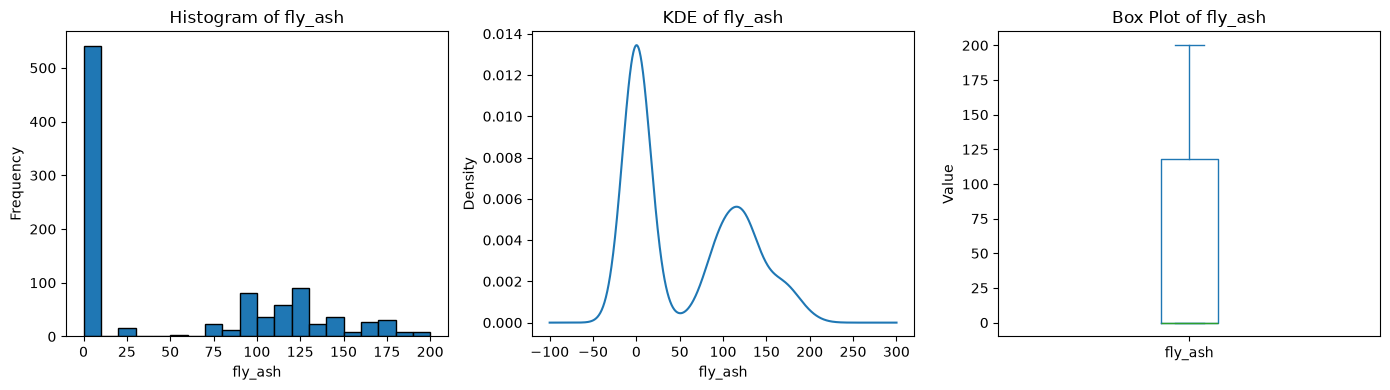

In [20]:
univariate_analysis(concrete_data_df, 'fly_ash')

## **4. `water`**

Analysis for: water

Summary Statistics:
count    1005.000000
mean      182.075323
std        21.339334
min       121.800000
25%       166.600000
50%       185.700000
75%       192.900000
max       247.000000
Name: water, dtype: float64

Skewness: 0.034



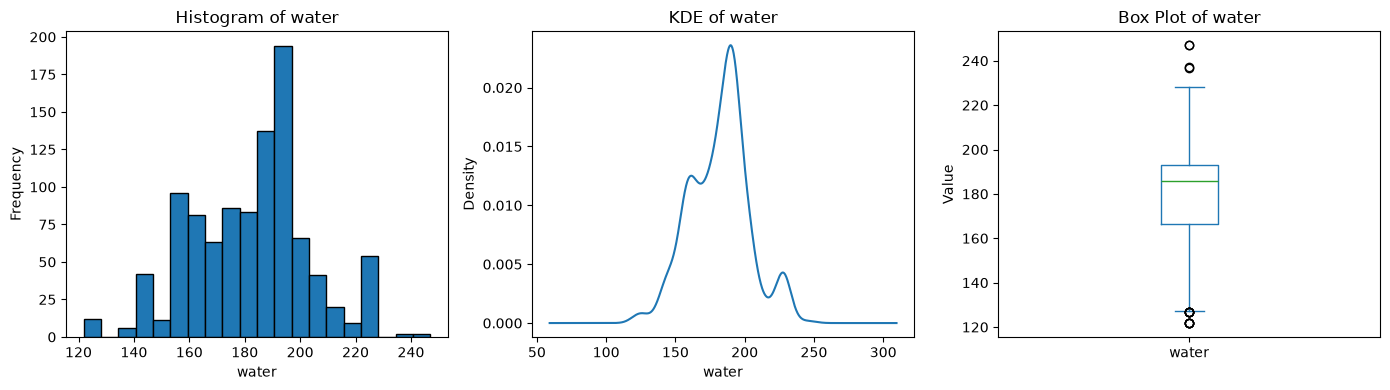

In [21]:
univariate_analysis(concrete_data_df, 'water')

## **5. `superplasticizer`**

Analysis for: superplasticizer

Summary Statistics:
count    1005.000000
mean        6.033234
std         5.919967
min         0.000000
25%         0.000000
50%         6.100000
75%        10.000000
max        32.200000
Name: superplasticizer, dtype: float64

Skewness: 0.981



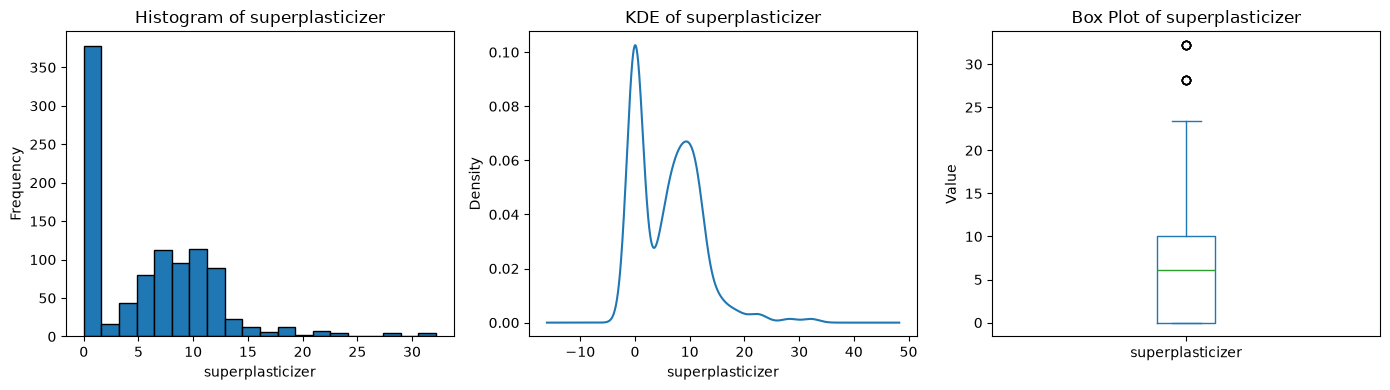

In [22]:
univariate_analysis(concrete_data_df, 'superplasticizer')

## **6. `coarse_aggregate`**

Analysis for: coarse_aggregate

Summary Statistics:
count    1005.000000
mean      974.376816
std        77.579667
min       801.000000
25%       932.000000
50%       968.000000
75%      1031.000000
max      1145.000000
Name: coarse_aggregate, dtype: float64

Skewness: -0.065



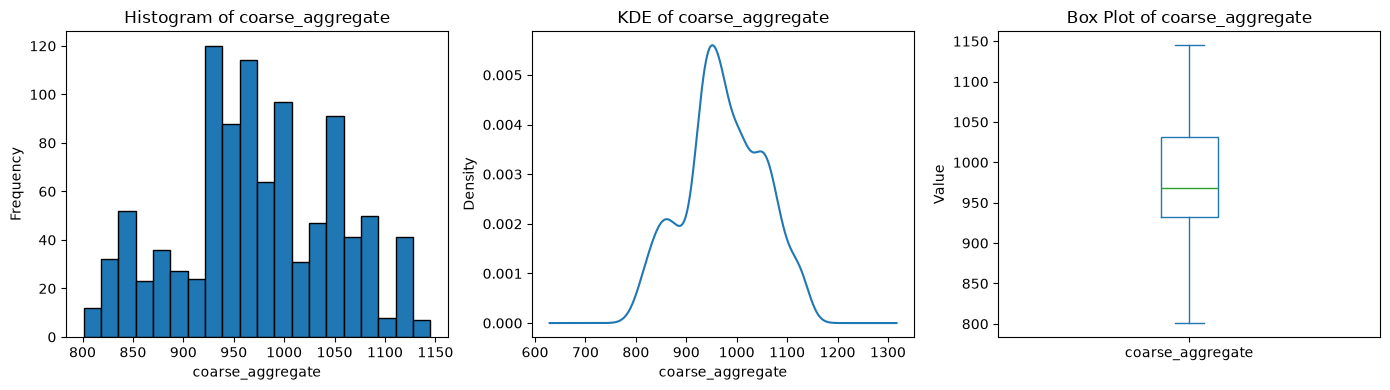

In [23]:
univariate_analysis(concrete_data_df, 'coarse_aggregate')

## **7. `fine_aggregate`**

Analysis for: fine_aggregate

Summary Statistics:
count    1005.000000
mean      772.688259
std        80.340435
min       594.000000
25%       724.300000
50%       780.000000
75%       822.200000
max       992.600000
Name: fine_aggregate, dtype: float64

Skewness: -0.252



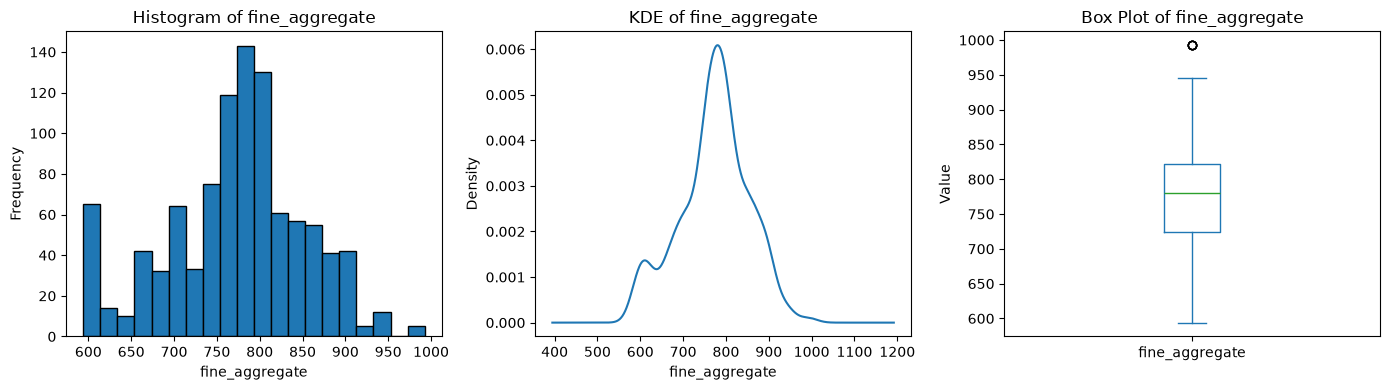

In [24]:
univariate_analysis(concrete_data_df, 'fine_aggregate')

## **8. `age`**

Analysis for: age

Summary Statistics:
count    1005.000000
mean       45.856716
std        63.734692
min         1.000000
25%         7.000000
50%        28.000000
75%        56.000000
max       365.000000
Name: age, dtype: float64

Skewness: 3.254



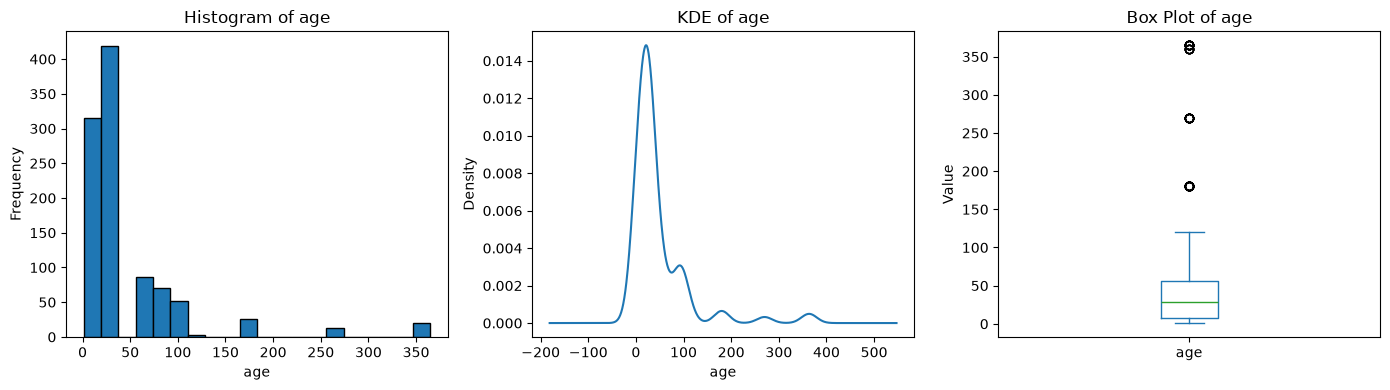

In [25]:
univariate_analysis(concrete_data_df, 'age')

## **Univariate Analysis on Target (Numerical Column)**

## **1. `concrete_compressive_strength`**

Analysis for: concrete_compressive_strength

Summary Statistics:
count    1005.000000
mean       35.250378
std        16.284815
min         2.330000
25%        23.520000
50%        33.800000
75%        44.870000
max        82.600000
Name: concrete_compressive_strength, dtype: float64

Skewness: 0.396



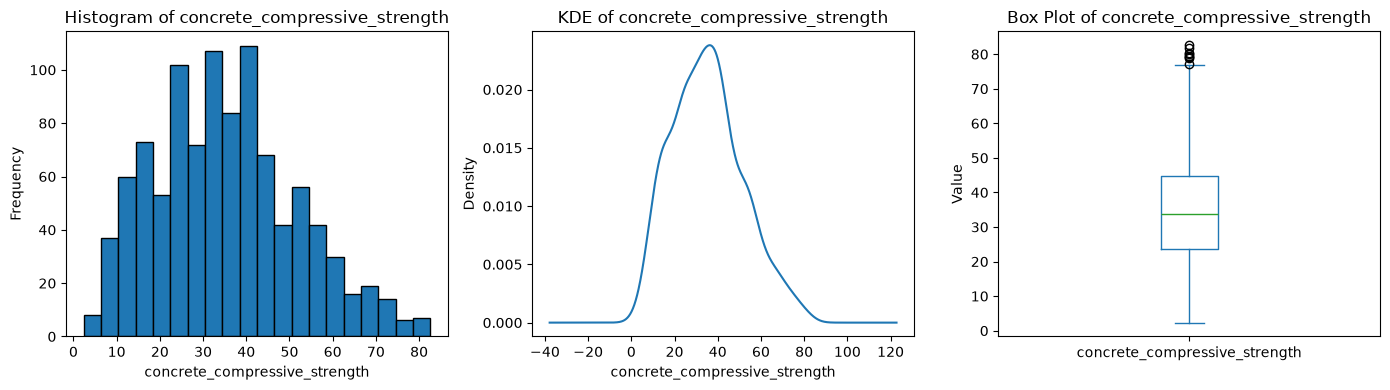

In [26]:
univariate_analysis(concrete_data_df, 'concrete_compressive_strength')

## **Bivariate Analysis on Target vs Numerical Column**

In [27]:
def bivariate_analysis_numerical(df, x_col, y_col, bins=30):
    """
    Perform bivariate analysis between two numerical columns.
    Displays Pearson correlation, scatter plot, 2D histogram, and 2D KDE plot.
    """
    print(f"{'='*60}")
    print(f"Analysis: {x_col} vs {y_col}")
    print(f"{'='*60}\n")

    # Pearson correlation
    r = df[x_col].corr(df[y_col])
    print(f"Pearson r: {round(r, 3)}\n")

    # Create subplots with more width
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Scatter Plot
    axes[0].scatter(df[x_col], df[y_col], alpha=0.5)
    axes[0].set_xlabel(x_col)
    axes[0].set_ylabel(y_col)
    axes[0].set_title(f'Scatter Plot')

    # 2D Histogram
    h = axes[1].hist2d(df[x_col], df[y_col], bins=bins)
    axes[1].set_xlabel(x_col)
    axes[1].set_ylabel(y_col)
    axes[1].set_title(f'2D Histogram')
    plt.colorbar(h[3], ax=axes[1], label='Count')

    # 2D KDE Plot
    sns.kdeplot(data=df, x=x_col, y=y_col, fill=False, ax=axes[2])
    axes[2].set_xlabel(x_col)
    axes[2].set_ylabel(y_col)
    axes[2].set_title(f'2D KDE')

    # Add main title for the whole figure
    fig.suptitle(f'{x_col} vs {y_col}', fontsize=14, fontweight='bold', y=1.02)

    plt.tight_layout()
    plt.show()



### **1. `concrete_compressive_strength` vs `cement`**

Analysis: cement vs concrete_compressive_strength

Pearson r: 0.488



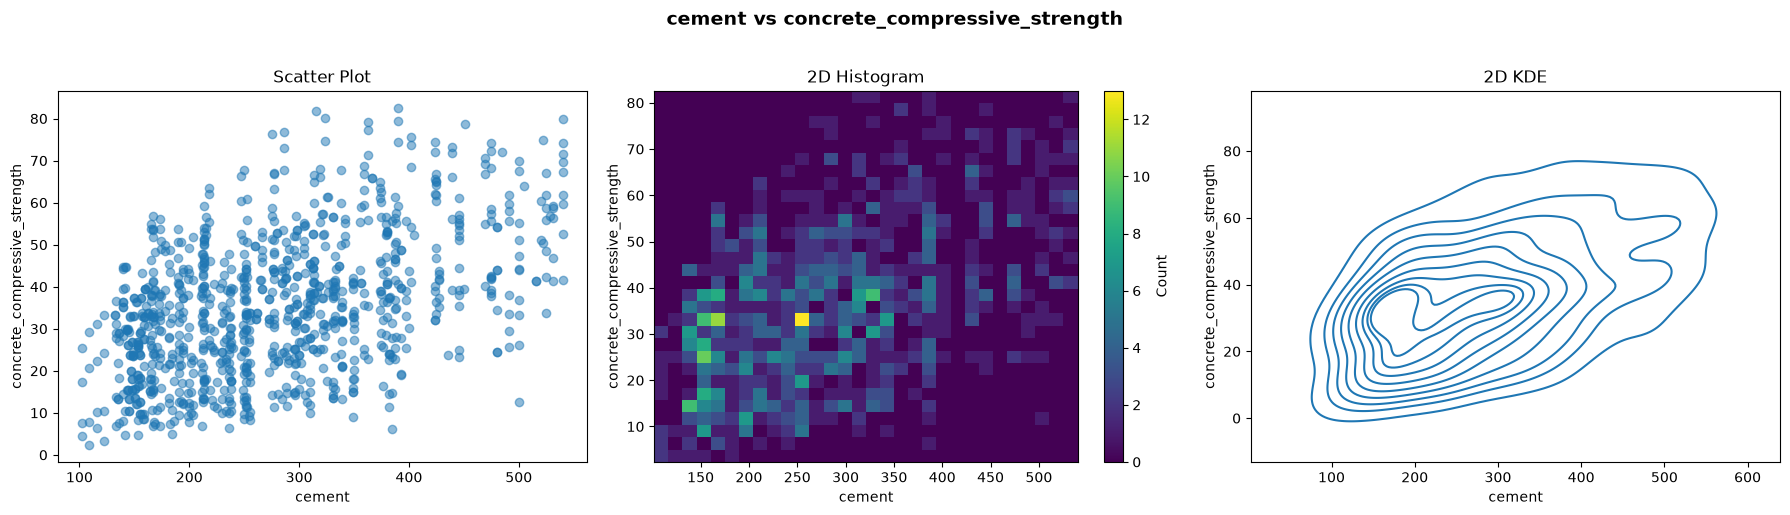

In [28]:
bivariate_analysis_numerical(concrete_data_df, 'cement', 'concrete_compressive_strength')

### **2. `concrete_compressive_strength` vs `blast_furnace_slag`**

Analysis: blast_furnace_slag vs concrete_compressive_strength

Pearson r: 0.103



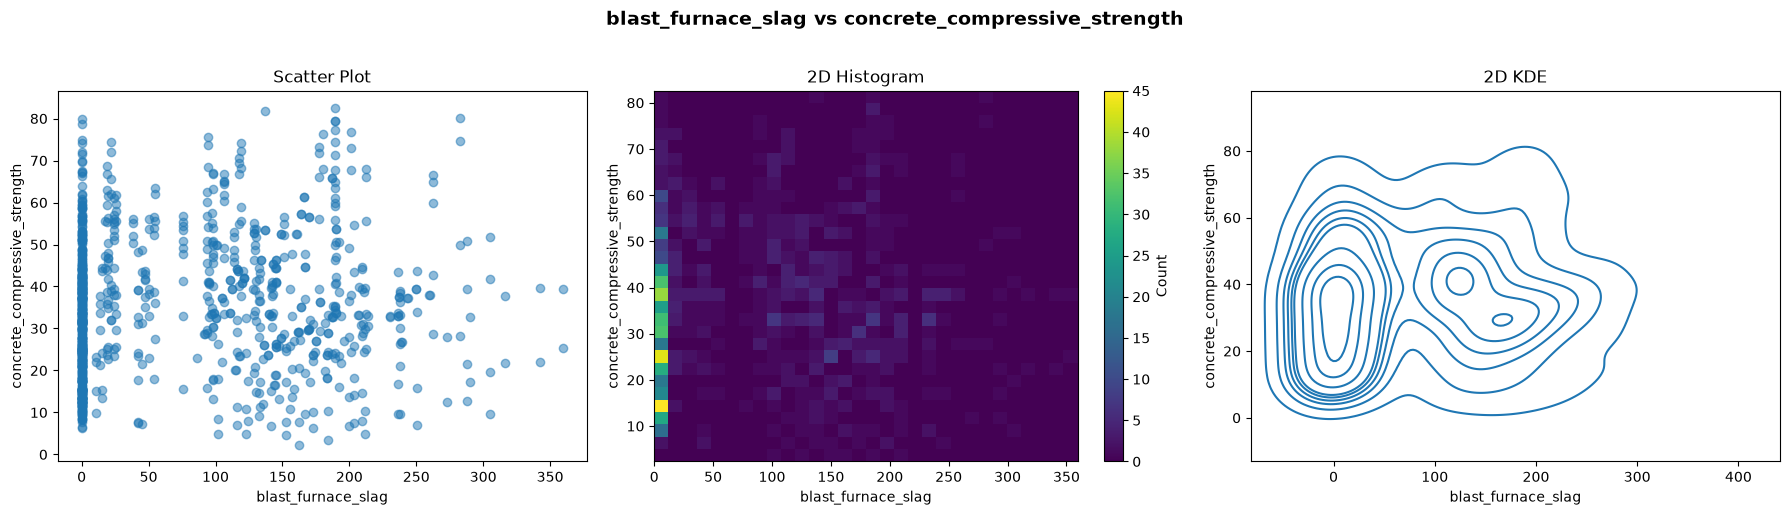

In [29]:
bivariate_analysis_numerical(concrete_data_df, 'blast_furnace_slag', 'concrete_compressive_strength')

### **3. `concrete_compressive_strength` vs `fly_ash`**

Analysis: fly_ash vs concrete_compressive_strength

Pearson r: -0.081



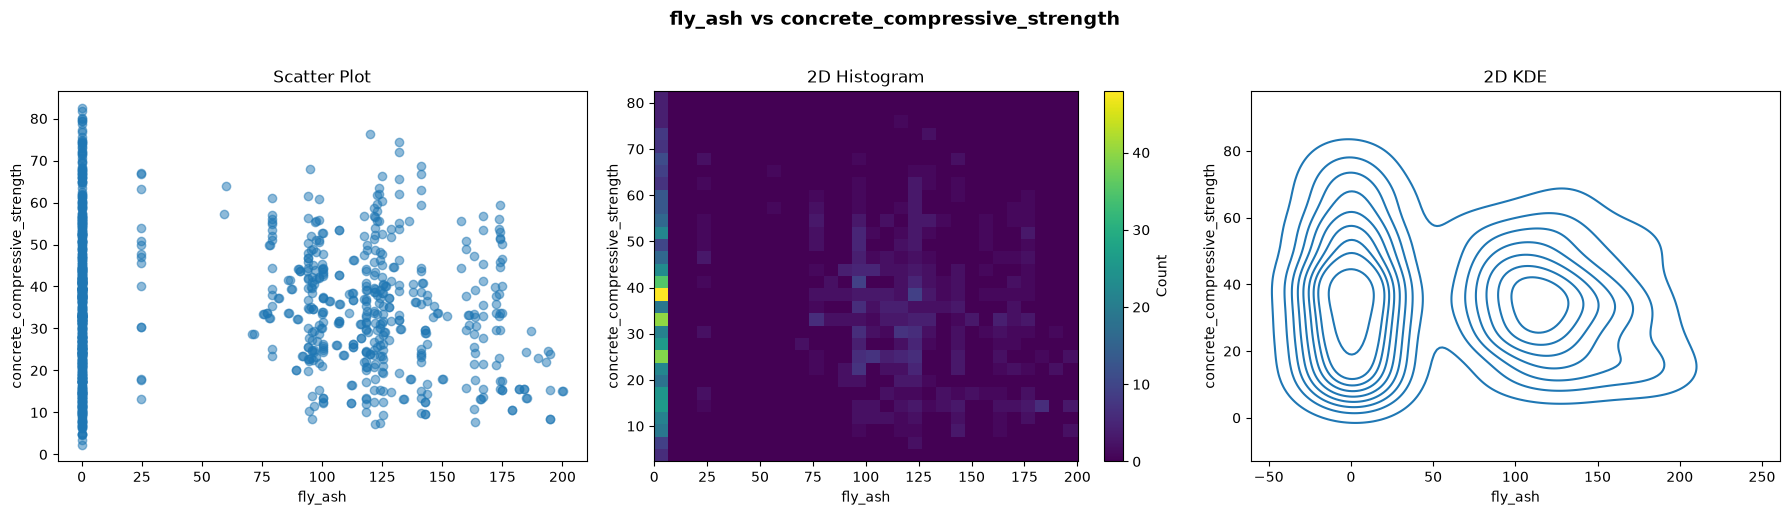

In [30]:
bivariate_analysis_numerical(concrete_data_df, 'fly_ash', 'concrete_compressive_strength')

### **4. `concrete_compressive_strength` vs `water`**

Analysis: water vs concrete_compressive_strength

Pearson r: -0.27



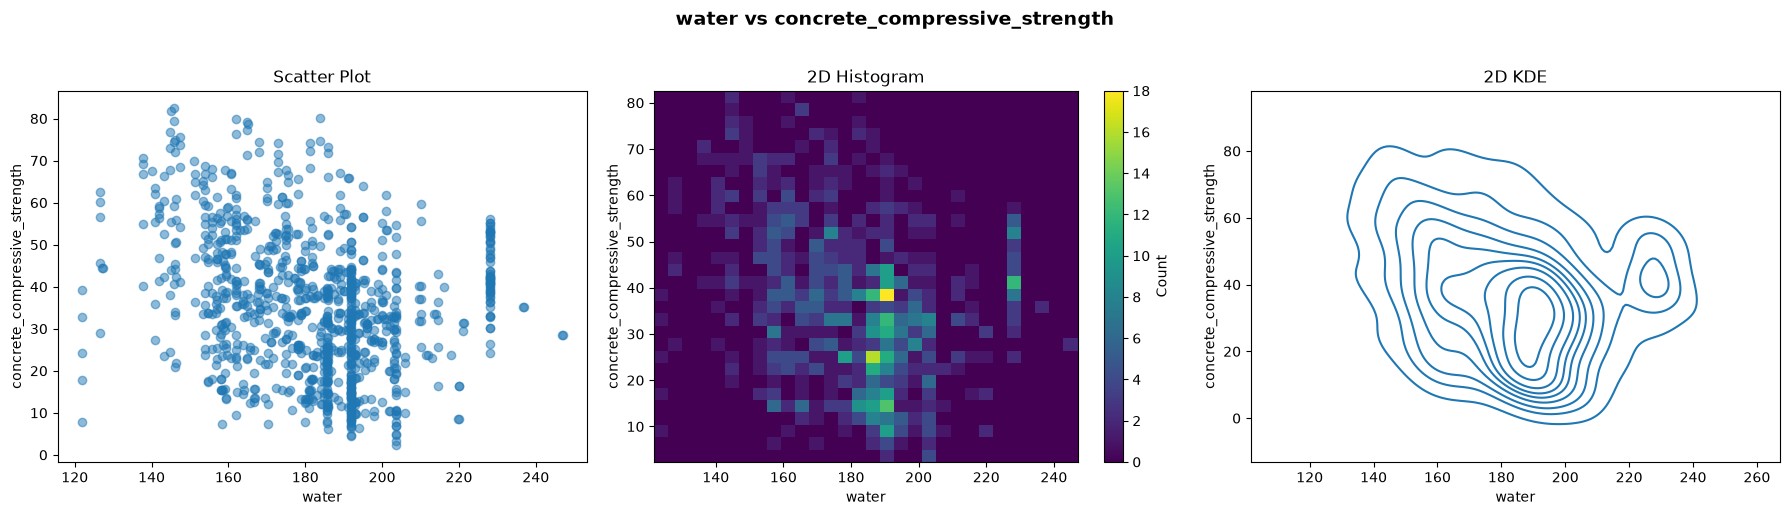

In [31]:
bivariate_analysis_numerical(concrete_data_df, 'water', 'concrete_compressive_strength')

### **5. `concrete_compressive_strength` vs `superplasticizer`**

Analysis: superplasticizer vs concrete_compressive_strength

Pearson r: 0.344



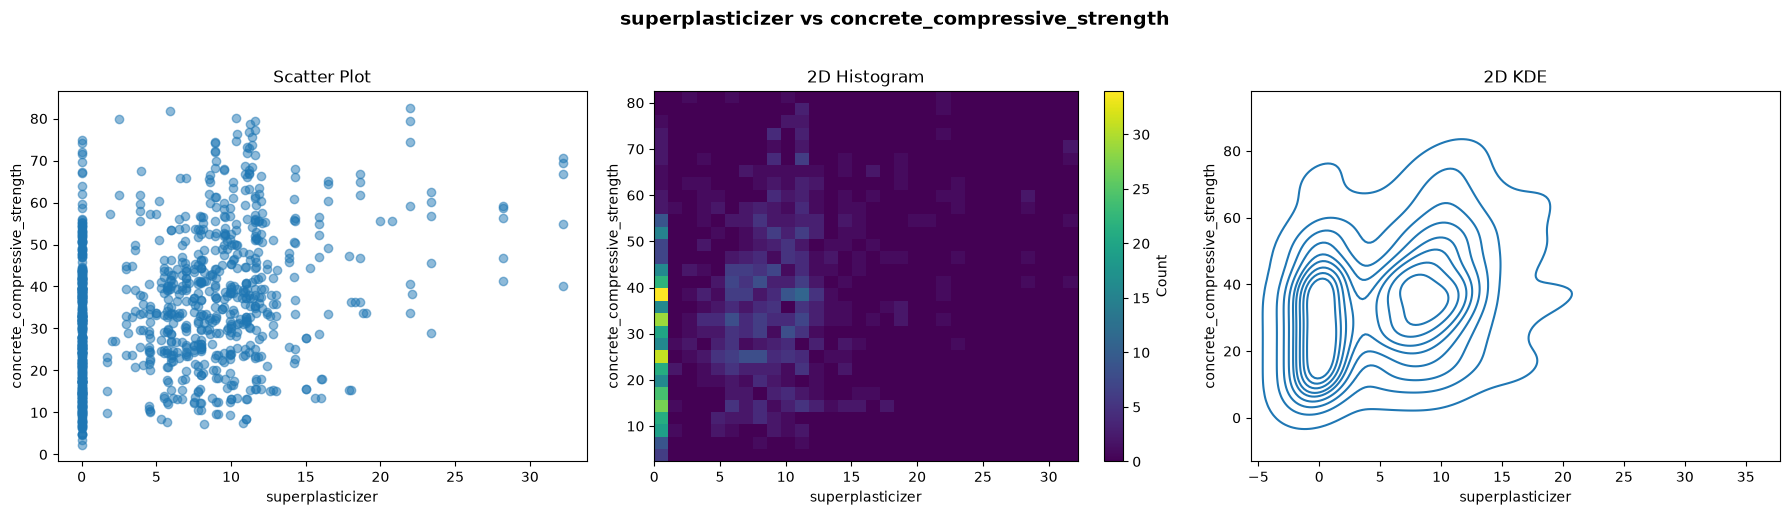

In [32]:
bivariate_analysis_numerical(concrete_data_df, 'superplasticizer', 'concrete_compressive_strength')

### **6. `concrete_compressive_strength` vs `coarse_aggregate`**

Analysis: coarse_aggregate vs concrete_compressive_strength

Pearson r: -0.145



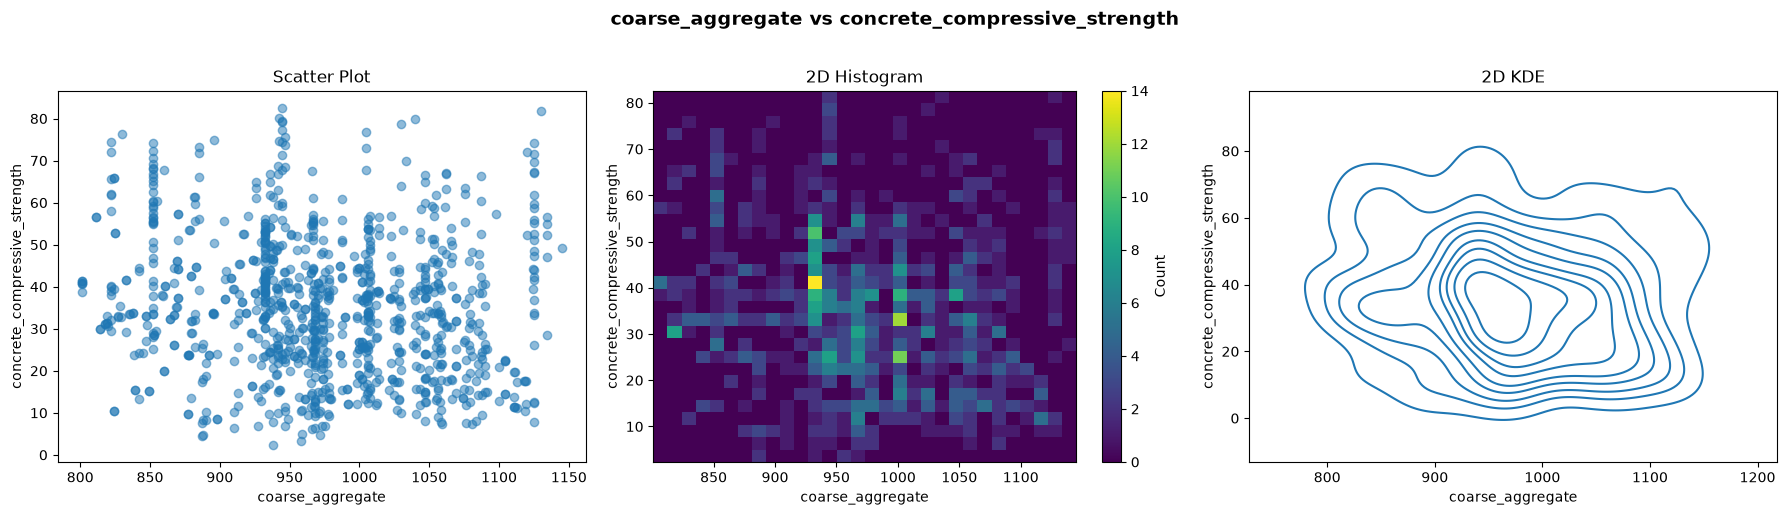

In [33]:
bivariate_analysis_numerical(concrete_data_df, 'coarse_aggregate', 'concrete_compressive_strength')

### **7. `concrete_compressive_strength` vs `fine_aggregate`**

Analysis: fine_aggregate vs concrete_compressive_strength

Pearson r: -0.186



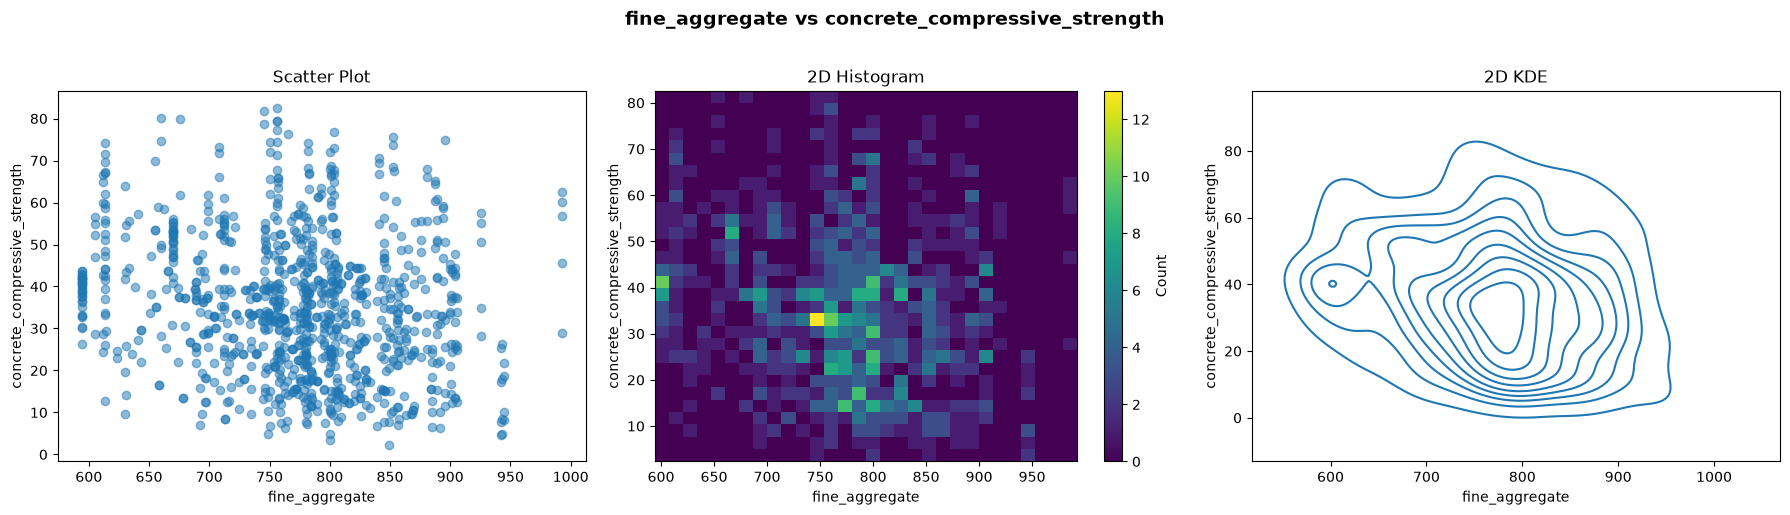

In [34]:
bivariate_analysis_numerical(concrete_data_df, 'fine_aggregate', 'concrete_compressive_strength')

### **8. `concrete_compressive_strength` vs `age`**

Analysis: age vs concrete_compressive_strength

Pearson r: 0.337



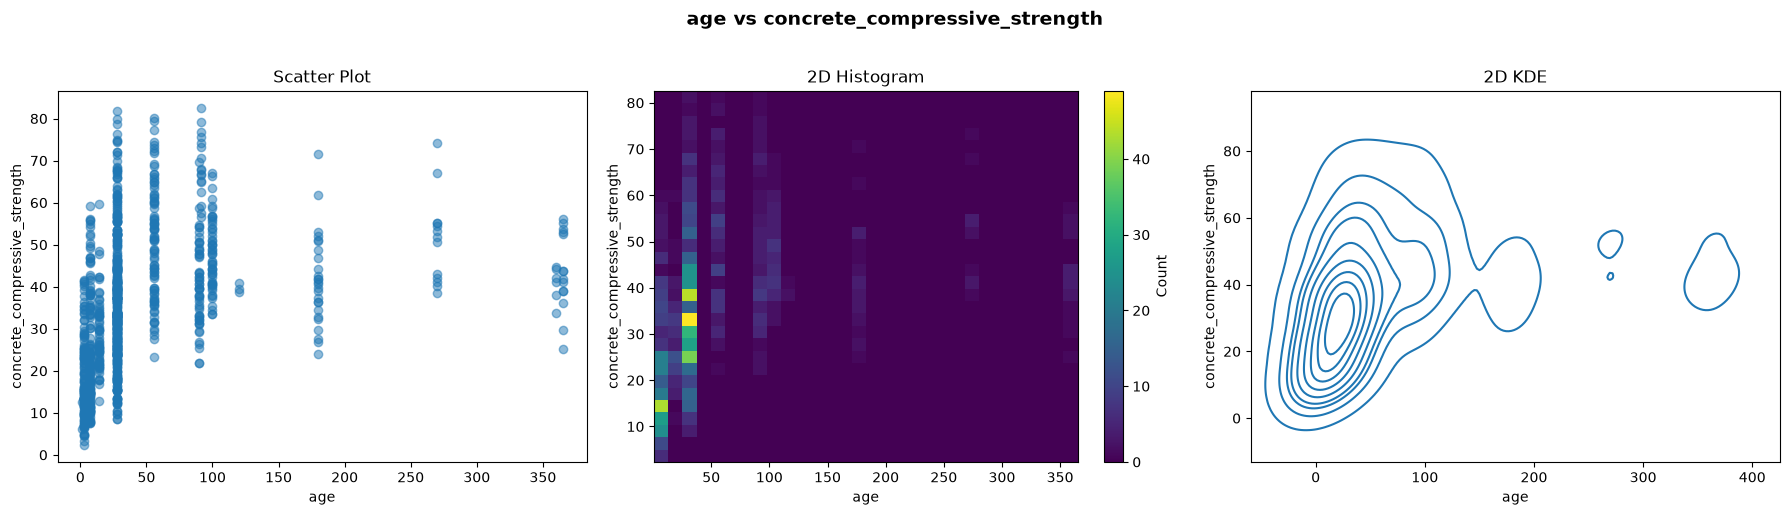

In [35]:
bivariate_analysis_numerical(concrete_data_df, 'age', 'concrete_compressive_strength')

## **Multivariate Analysis**

In [36]:
# Computing the correlation matrix for numeric columns only.
corr_matrix = concrete_data_df.corr(numeric_only=True)
corr_matrix

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
cement,1.000000,-0.303324,-0.385610,-0.056625,0.060906,-0.086205,-0.245375,0.086348,0.488283
blast_furnace_slag,-0.303324,1.000000,-0.312352,0.130262,0.019800,-0.277559,-0.289685,-0.042759,0.103374
fly_ash,-0.385610,-0.312352,1.000000,-0.283314,0.414213,-0.026468,0.090262,-0.158940,-0.080648
water,-0.056625,0.130262,-0.283314,1.000000,-0.646946,-0.212480,-0.444915,0.279284,-0.269624
superplasticizer,0.060906,0.019800,0.414213,-0.646946,1.000000,-0.241721,0.207993,-0.194076,0.344209
coarse_aggregate,-0.086205,-0.277559,-0.026468,-0.212480,-0.241721,1.000000,-0.162187,-0.005264,-0.144717
fine_aggregate,-0.245375,-0.289685,0.090262,-0.444915,0.207993,-0.162187,1.000000,-0.156572,-0.186448
age,0.086348,-0.042759,-0.158940,0.279284,-0.194076,-0.005264,-0.156572,1.000000,0.337367
concrete_compressive_strength,0.488283,0.103374,-0.080648,-0.269624,0.344209,-0.144717,-0.186448,0.337367,1.000000


In [37]:
# Calculate the correlation of every numeric feature with concrete compressive strength
concrete_data_df.corr(numeric_only=True)["concrete_compressive_strength"].sort_values(ascending=False)



concrete_compressive_strength    1.000000
cement                           0.488283
superplasticizer                 0.344209
age                              0.337367
blast_furnace_slag               0.103374
fly_ash                         -0.080648
coarse_aggregate                -0.144717
fine_aggregate                  -0.186448
water                           -0.269624
Name: concrete_compressive_strength, dtype: float64

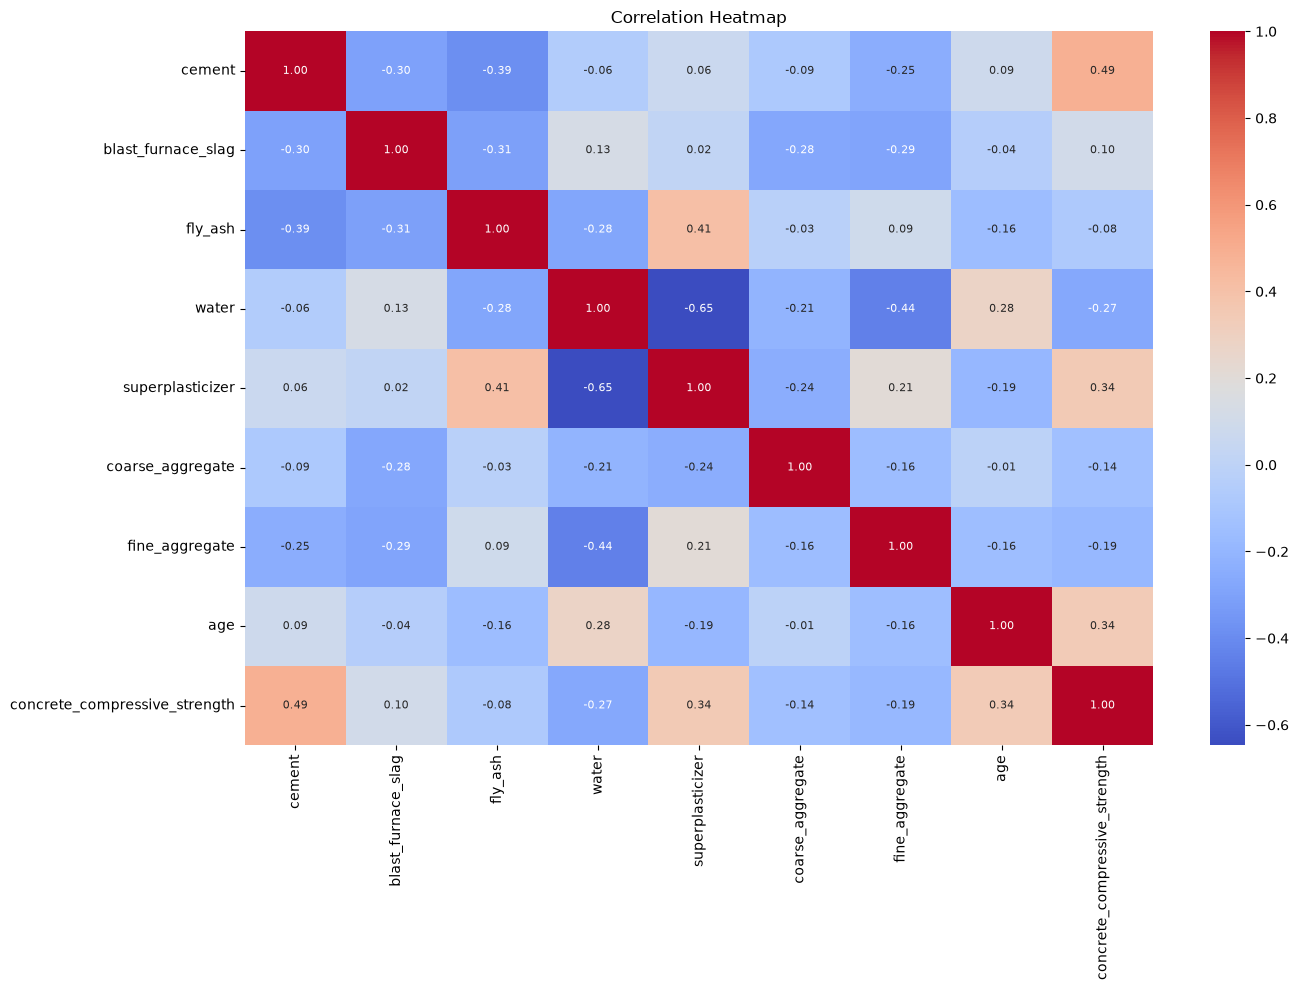

In [38]:
# Correlation Heatmap
plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size":8})
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


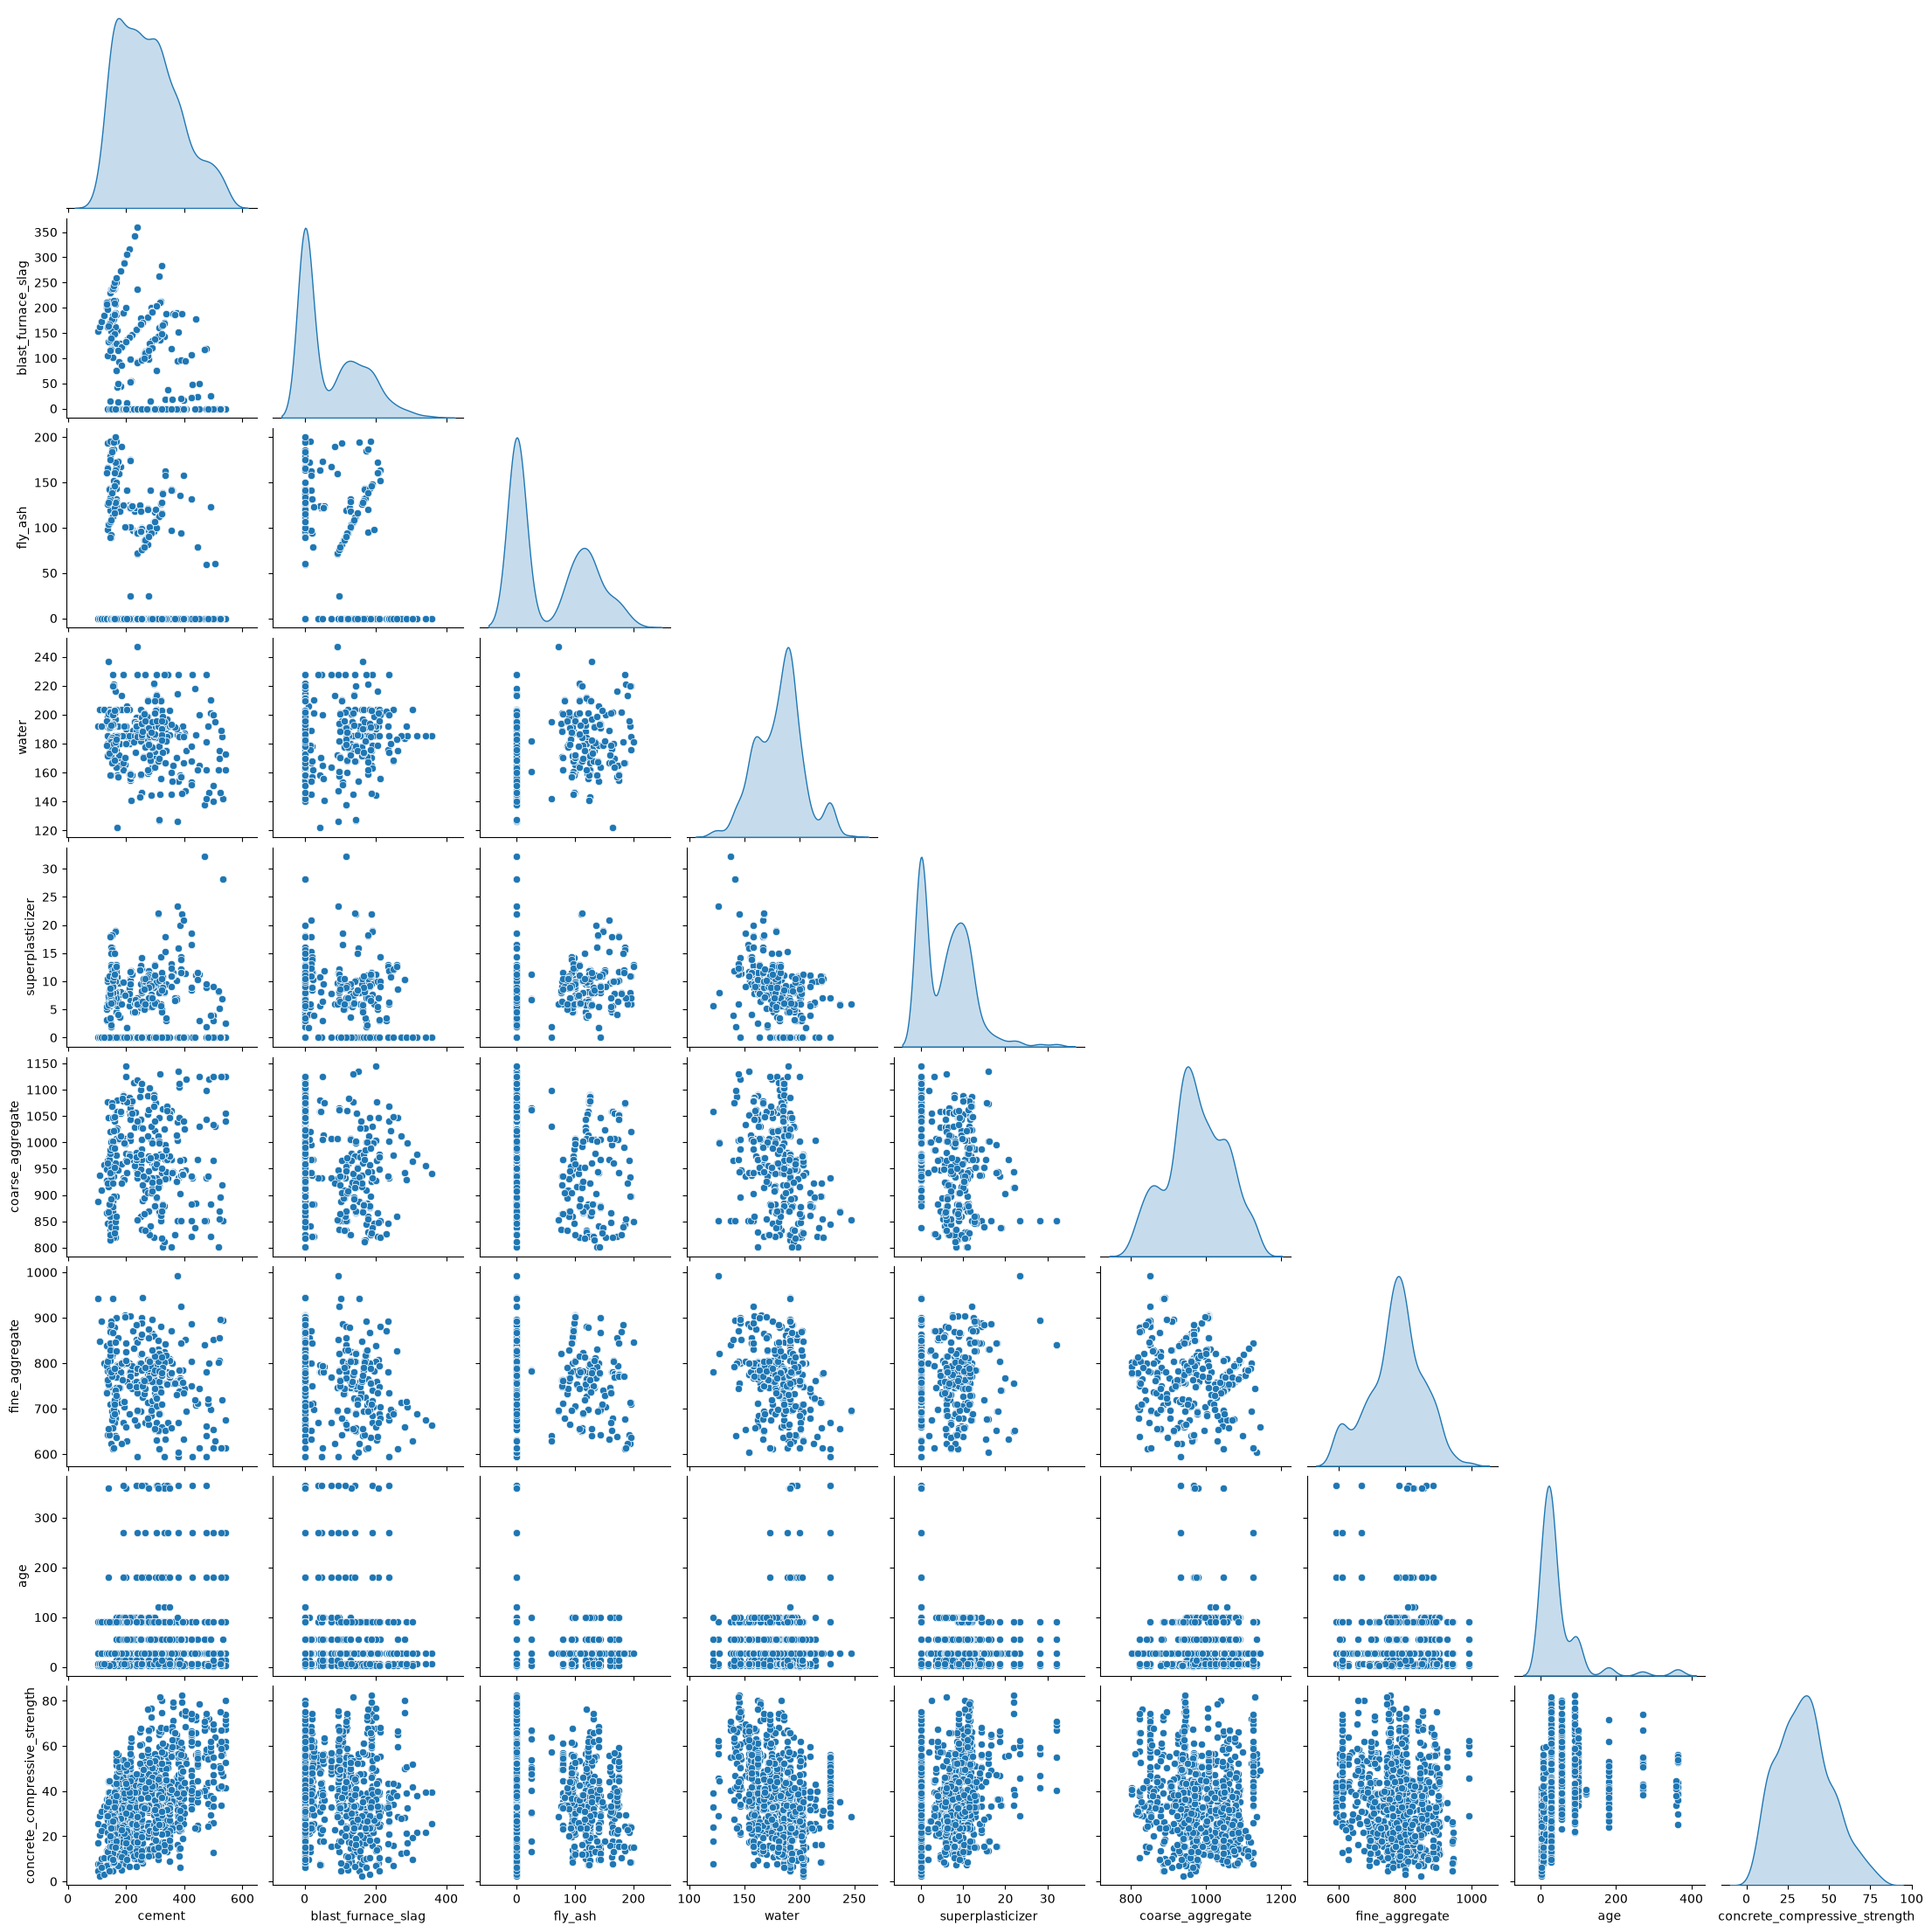

In [39]:
# Create a pairplot to visualise relationships between numerical variables.
num_cols = concrete_data_df.select_dtypes(include="number").columns
sns.pairplot(concrete_data_df[num_cols], diag_kind="kde", corner=True)
plt.show()

In [40]:
# Outliers Inspection
def iqr_outlier_summary(df, cols):
    rows = []
    for c in cols:
        if c not in concrete_data_df.columns:
            continue
        if not pd.api.types.is_numeric_dtype(df[c]):
            continue
        q1, q3 = df[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
        out = ((df[c] < lo) | (df[c] > hi)).sum()
        rows.append([c, float(q1), float(q3), float(iqr), float(lo), float(hi), int(out), round(out/len(df)*100, 2)])
    return pd.DataFrame(rows, columns=["column","Q1","Q3","IQR","lower_bound","upper_bound","outliers_n","outliers_%"])

numeric_candidates = [
    "cement", "blast_furnace_slag", "fly_ash", "water",
    "superplasticizer", "coarse_aggregate", "fine_aggregate",
    "age", "concrete_compressive_strength"
]
outlier_table = iqr_outlier_summary(concrete_data_df, numeric_candidates)
display(outlier_table.sort_values("outliers_%", ascending=False).head(15))



,column,Q1,Q3,IQR,lower_bound,upper_bound,outliers_n,outliers_%
7,age,7.00,56.00,49.00,-66.500,129.500,59,5.87
3,water,166.60,192.90,26.30,127.150,232.350,15,1.49
4,superplasticizer,0.00,10.00,10.00,-15.000,25.000,10,1.00
8,concrete_compressive_strength,23.52,44.87,21.35,-8.505,76.895,8,0.80
6,fine_aggregate,724.30,822.20,97.90,577.450,969.050,5,0.50
1,blast_furnace_slag,0.00,142.50,142.50,-213.750,356.250,2,0.20
0,cement,190.70,349.00,158.30,-46.750,586.450,0,0.00
2,fly_ash,0.00,118.30,118.30,-177.450,295.750,0,0.00
5,coarse_aggregate,932.00,1031.00,99.00,783.500,1179.500,0,0.00


In [41]:
# Importing Libraries

# Preprocessing & Model Selection
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Evaluation Metrics
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Features Importance
from sklearn.inspection import permutation_importance

# # Statistical Analysis
from scipy import stats



In [42]:
# Define Features and Target

df = concrete_data_df.copy()

Target = "concrete_compressive_strength"

numerical_features = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
    "age"
]

# All input features
all_features = numerical_features

# Check that required columns exist
missing_cols = [c for c in all_features + [Target] if c not in df.columns]

if missing_cols:
    raise ValueError(f"Missing columns in df: {missing_cols}")

# Independent variables
X = df[all_features].copy()

# Dependent variable
y = df[Target].copy()

print("X Shape:", X.shape)
print("y Shape:", y.shape)


X Shape: (1005, 8)
y Shape: (1005,)


In [43]:
# Single Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Train Samples:", X_train.shape[0])
print("Test Samples :", X_test.shape[0])



Train Samples: 804
Test Samples : 201


In [44]:
# Linear Regression Pipeline
linear_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])


# Random Forest Model
random_forest = RandomForestRegressor(
    random_state=42
)


In [45]:
# Cross-Validation Setup and Scoring (Training Only)
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation Metrics
scoring = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2"
}


def quick_cv_table(models, X, y, cv, scoring):
    rows = []

    for name, model in models.items():
        scores = cross_validate(
            model,
            X,
            y,
            cv=cv,
            scoring=scoring,
            n_jobs=-1
        )

        rows.append({
            "Model": name,
            "CV_RMSE": -scores["test_RMSE"].mean(),
            "CV_MAE": -scores["test_MAE"].mean(),
            "CV_R2": scores["test_R2"].mean()
        })

    return pd.DataFrame(rows).sort_values("CV_RMSE")


In [46]:
# Baseline Models
baseline_models = {
    "Linear Regression": linear_pipeline,
    "Random Forest": random_forest
}

# Perform cross-validation on training data only
baseline_cv = quick_cv_table(
    baseline_models,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("=" * 60)
print("BASELINE CV RESULTS (Training Data Only)")
print("=" * 60)

print(baseline_cv.to_string(index=False))

BASELINE CV RESULTS (Training Data Only)
            Model   CV_RMSE   CV_MAE    CV_R2
    Random Forest  5.361252 3.880415 0.885663
Linear Regression 10.201933 8.099553 0.589524


In [47]:
# ============================================================
# Train vs CV RMSE Gap
# ============================================================

def train_cv_gap(model, name):

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    train_rmse = -scores["train_RMSE"].mean()
    cv_rmse = -scores["test_RMSE"].mean()

    return {
        "Model": name,
        "Train_RMSE": train_rmse,
        "CV_RMSE": cv_rmse,
        "Gap(CV-Train)": cv_rmse - train_rmse
    }


gap_df = pd.DataFrame([
    train_cv_gap(linear_pipeline, "Linear Regression"),
    train_cv_gap(random_forest, "Random Forest")
])

gap_df

,Model,Train_RMSE,CV_RMSE,Gap(CV-Train)
0,Linear Regression,9.979424,10.201933,0.222510
1,Random Forest,2.133155,5.361252,3.228096


In [48]:
# ============================================================
# Learning Curve for Both Models (Training Data Only)
# ============================================================

def plot_learning_curve(estimator, X, y, title, scoring_metric="r2"):

    train_sizes = np.linspace(0.1, 1.0, 10)

    sizes_abs, train_scores, val_scores = learning_curve(
        estimator=estimator,
        X=X,
        y=y,
        train_sizes=train_sizes,
        cv=cv,
        scoring=scoring_metric,
        n_jobs=-1
    )

    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)

    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)

    plt.figure(figsize=(8, 5))
    plt.plot(sizes_abs, train_mean, marker="o", label="Training")
    plt.plot(sizes_abs, val_mean, marker="o", label="Validation (CV)")

    plt.fill_between(sizes_abs, train_mean - train_std, train_mean + train_std, alpha=0.2)
    plt.fill_between(sizes_abs, val_mean - val_std, val_mean + val_std, alpha=0.2)

    plt.xlabel("Training Set Size")
    plt.ylabel("R² Score")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

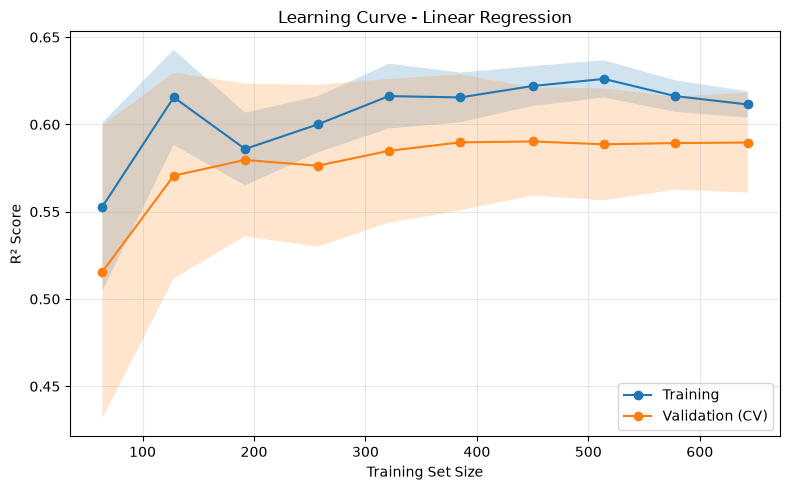

In [49]:
# Learning Curve for Linear Regression
plot_learning_curve(
    linear_pipeline,
    X_train,
    y_train,
    "Learning Curve - Linear Regression"
)

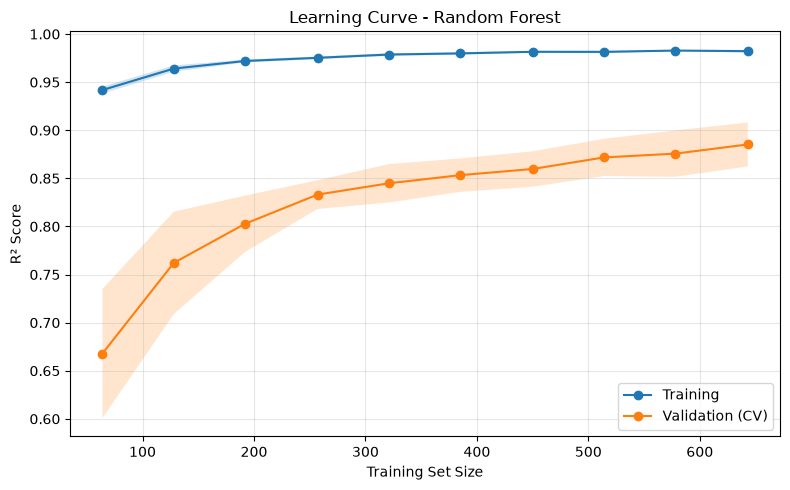

In [50]:
# Learning Curve for Randomforestregressor
plot_learning_curve(
    random_forest,
    X_train,
    y_train,
    "Learning Curve - Random Forest"
)

In [51]:
# ============================================================
# Fit Both Models on Full Training Set
# ============================================================

linear_pipeline.fit(X_train, y_train)
random_forest.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [52]:
# ============================================================
# Evaluate Both Models Once on the Test Set
# ============================================================

def test_eval(name, model):
    pred = model.predict(X_test)

    return {
        "Model": name,
        "Test_MAE": mean_absolute_error(y_test, pred),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test_R2": r2_score(y_test, pred)
    }


test_df = pd.DataFrame([
    test_eval("Linear Regression", linear_pipeline),
    test_eval("Random Forest", random_forest)
]).sort_values("Test_RMSE")


print("=" * 55)
print("FINAL TEST RESULTS")
print("=" * 55)

print(test_df.to_string(index=False))

FINAL TEST RESULTS
            Model  Test_MAE  Test_RMSE  Test_R2
    Random Forest  3.484102   5.249632 0.907622
Linear Regression  8.895256  11.191320 0.580170


In [53]:
# ============================================================
# Permutation Feature Importance - Random Forest
# ============================================================

final_model = random_forest
best_name = "Random Forest"

perm = permutation_importance(
    final_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    n_jobs=-1,
    scoring="neg_root_mean_squared_error"
)

imp_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std
}).sort_values(
    "Importance_Mean",
    ascending=False
)

print("FEATURE IMPORTANCE")
print(imp_df.to_string(index=False))

FEATURE IMPORTANCE
           Feature  Importance_Mean  Importance_Std
               age        10.555657        0.583778
            cement         8.951250        0.719631
blast_furnace_slag         3.177308        0.298952
  superplasticizer         2.496781        0.265944
             water         2.433782        0.188431
    fine_aggregate         1.050068        0.116800
  coarse_aggregate         0.389585        0.096062
           fly_ash         0.211715        0.028428


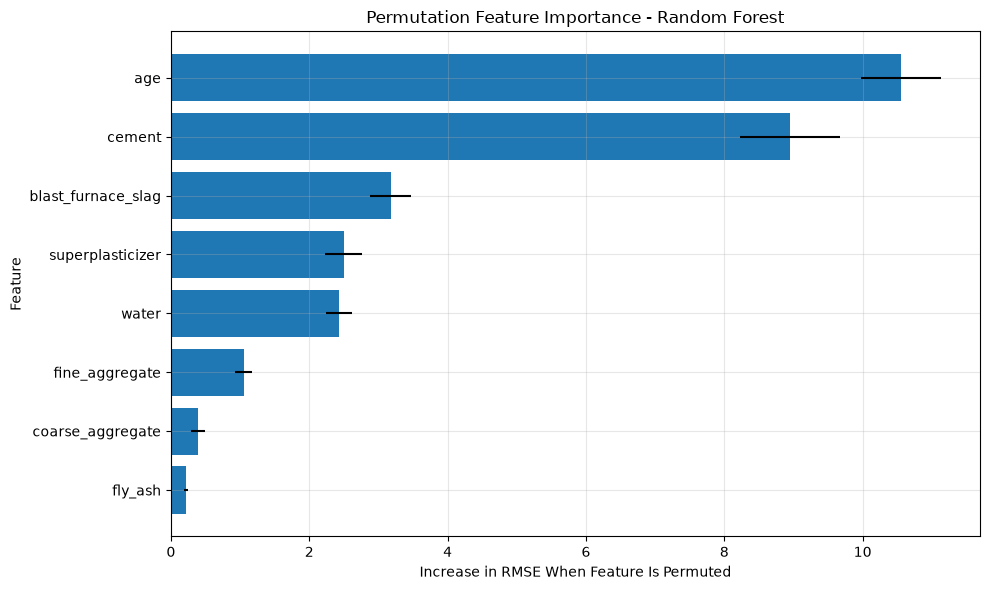

In [54]:
# Plot Feature Importance

plt.figure(figsize=(10, 6))

plot_data = imp_df.iloc[::-1]

plt.barh(
    plot_data["Feature"],
    plot_data["Importance_Mean"],
    xerr=plot_data["Importance_Std"]
)

plt.xlabel("Increase in RMSE When Feature Is Permuted")
plt.ylabel("Feature")
plt.title(f"Permutation Feature Importance - {best_name}")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [55]:
# ============================================================
# Residual Analysis - Test Set Only
# ============================================================

def residual_diagnostics(model, X_test, y_test, model_name="Model"):

    # Predictions
    y_pred = model.predict(X_test)

    # Residuals
    residuals = y_test - y_pred

    fig, axes = plt.subplots(2, 2, figsize=(14, 12))

    # 1. Actual vs Predicted
    ax1 = axes[0, 0]

    ax1.scatter(y_test, y_pred, alpha=0.6, edgecolors="black", linewidth=0.5)

    min_v = min(y_test.min(), y_pred.min())
    max_v = max(y_test.max(), y_pred.max())

    ax1.plot([min_v, max_v], [min_v, max_v], "r--", lw=2, label="Perfect Prediction")

    ax1.set_xlabel("Actual Concrete Strength (MPa)")
    ax1.set_ylabel("Predicted Concrete Strength (MPa)")
    ax1.set_title(f"Actual vs Predicted ({model_name})")
    ax1.legend()
    ax1.grid(True, alpha=0.3)


    # 2. Residuals vs Predicted
    ax2 = axes[0, 1]

    ax2.scatter(y_pred, residuals, alpha=0.6, edgecolors="black", linewidth=0.5)

    ax2.axhline(y=0, color="red", linestyle="--", lw=2)

    ax2.set_xlabel("Predicted Concrete Strength (MPa)")
    ax2.set_ylabel("Residuals (Actual - Predicted)")
    ax2.set_title("Residuals vs Predicted")
    ax2.grid(True, alpha=0.3)


    # 3. Residual Distribution
    ax3 = axes[1, 0]
    ax3.hist(residuals, bins=30, edgecolor="black", alpha=0.7, density=True)
    mu, sigma = stats.norm.fit(residuals)
    x = np.linspace(residuals.min(), residuals.max(), 200)
    ax3.plot(x, stats.norm.pdf(x, mu, sigma), "r-", lw=2, label=f"Normal Fit\nμ={mu:.2f}, σ={sigma:.2f}")

    ax3.set_xlabel("Residuals (MPa)")
    ax3.set_ylabel("Density")
    ax3.set_title("Residual Distribution")
    ax3.legend()
    ax3.grid(True, alpha=0.3)


    # 4. Q-Q Plot
    ax4 = axes[1, 1]
    stats.probplot(residuals, dist="norm", plot=ax4)
    ax4.set_title("Q-Q Plot")
    ax4.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

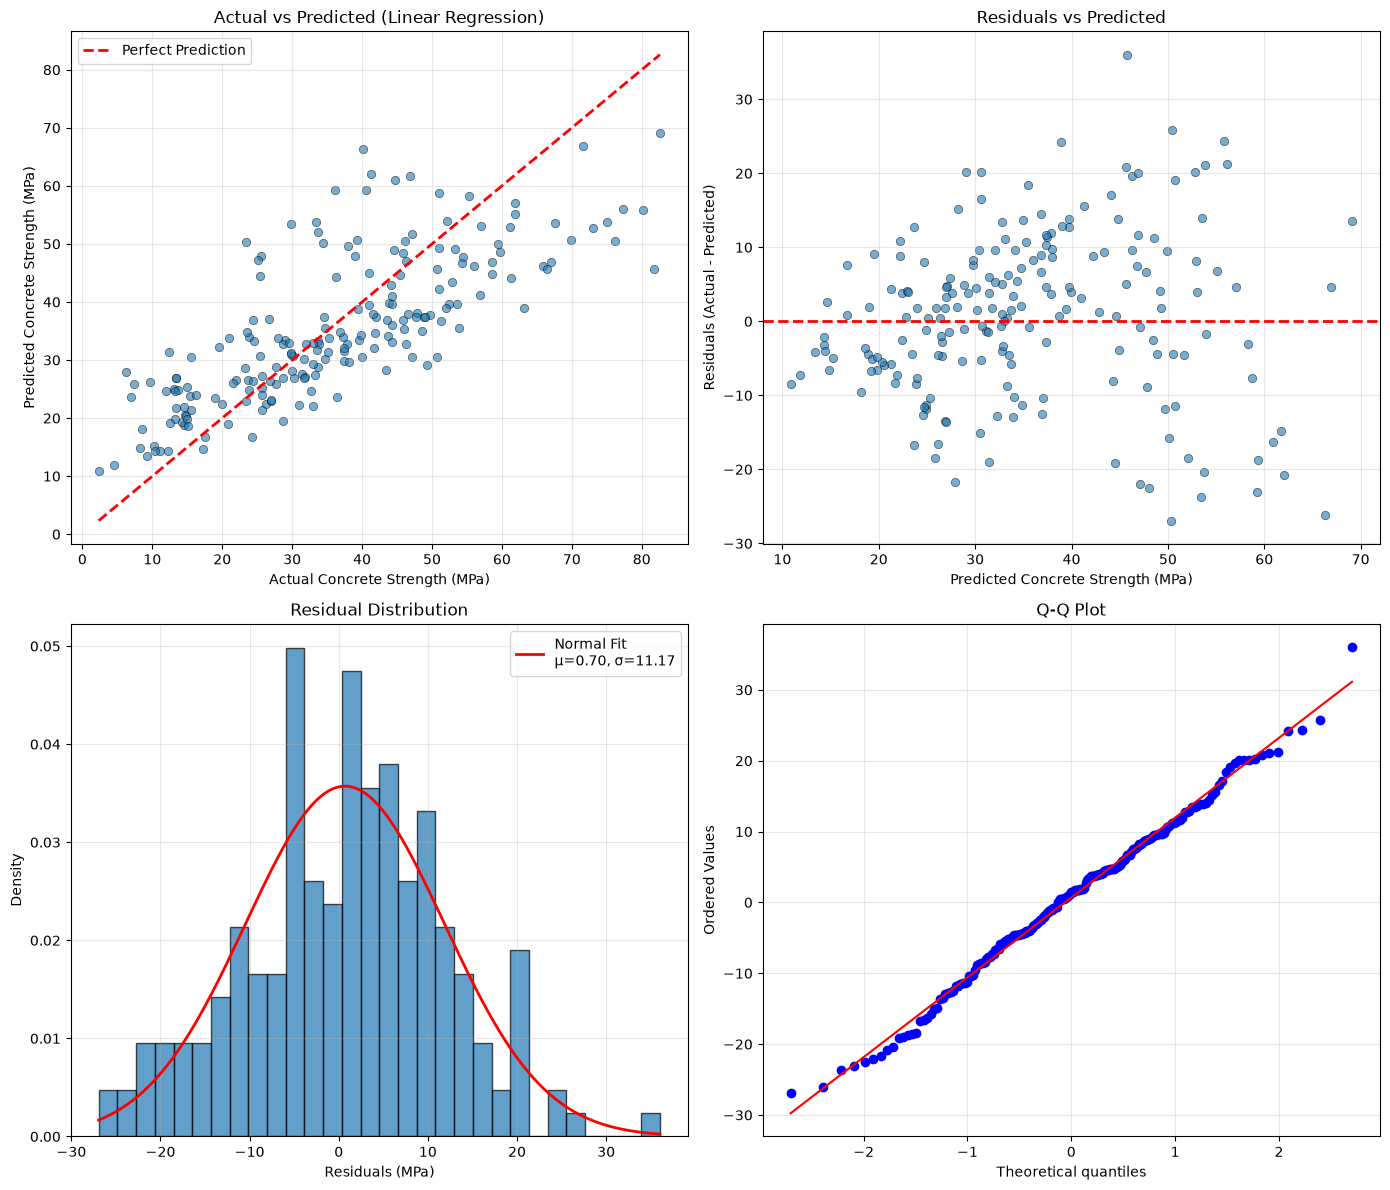

In [56]:
# Linear regression residual diagnostics
residual_diagnostics(
    linear_pipeline,
    X_test,
    y_test,
    model_name="Linear Regression"
)

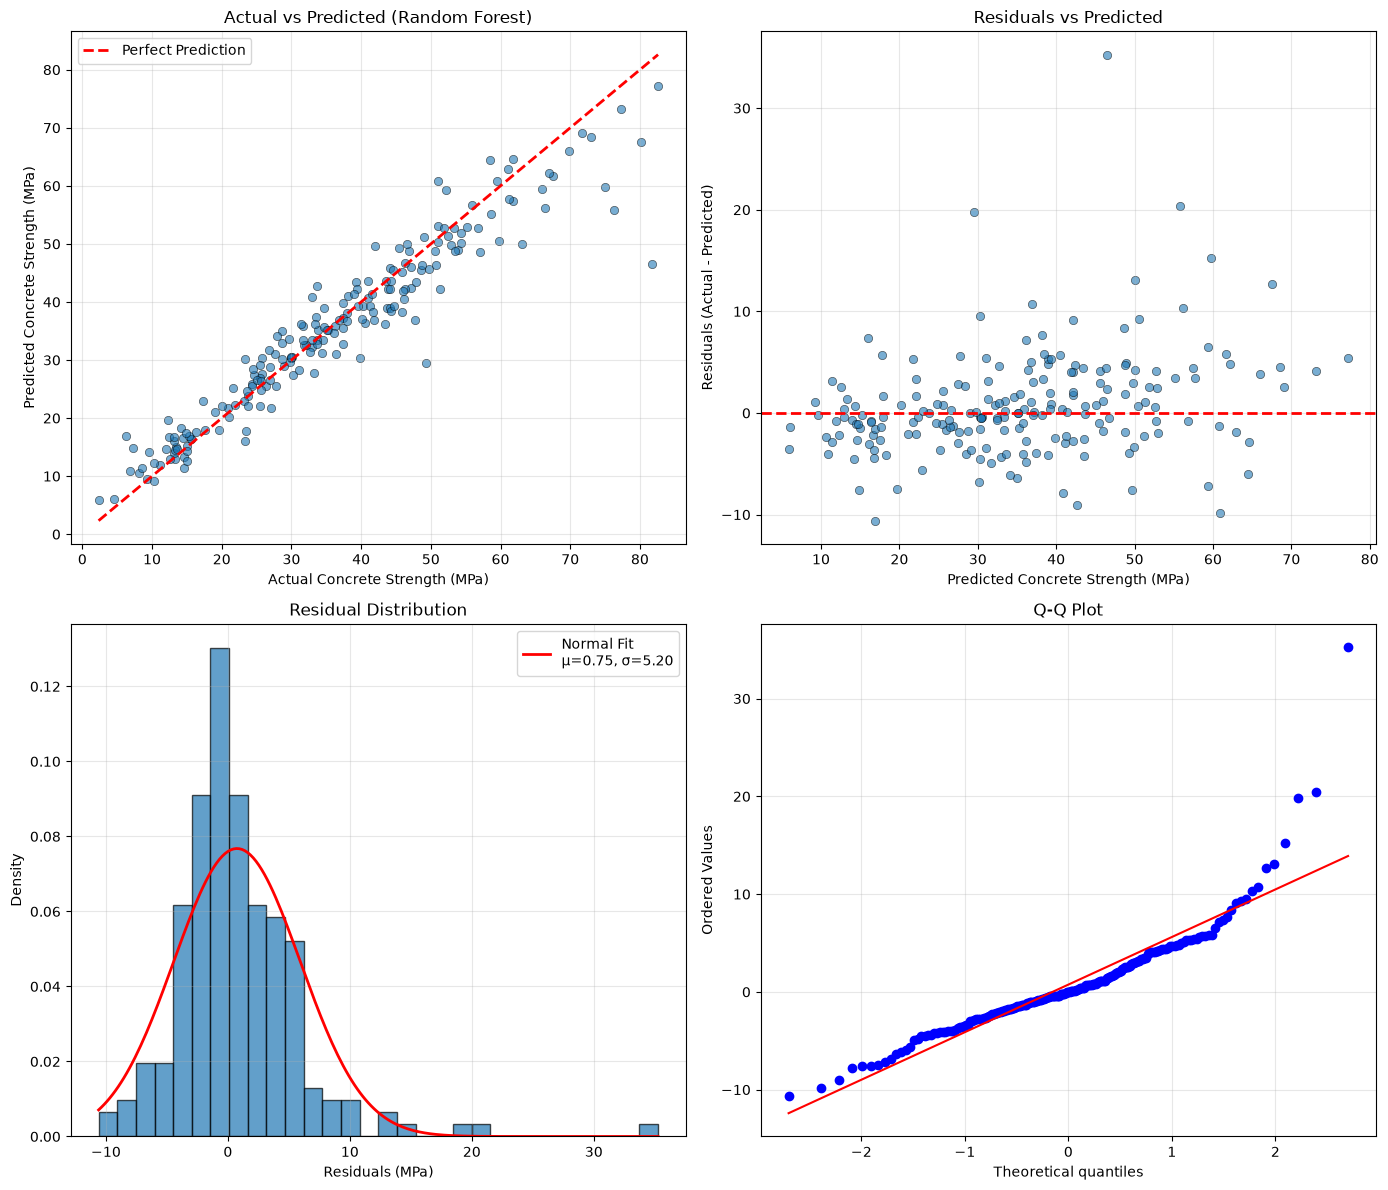

In [57]:
# Randomforestregressor residual diagnostics
residual_diagnostics(
    random_forest,
    X_test,
    y_test,
    model_name="Random Forest"
)


In [58]:
from pathlib import Path
import joblib

model_dir = Path.cwd().parent / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Save final Random Forest model
joblib.dump(
    random_forest,
    model_dir / "concrete_strength_model.joblib"
)

print("Model saved successfully.")
print("Model saved to:", model_dir / "concrete_strength_model.joblib")

Model saved successfully.
Model saved to: c:\Users\Acer\Desktop\concrete_strength_system\ml\models\concrete_strength_model.joblib


In [59]:
# Save model information
import json

# Get Random Forest test predictions
y_pred_rf = random_forest.predict(X_test)

model_info = {
    "model_name": "Random Forest Regressor",
    "features": [
        "cement",
        "blast_furnace_slag",
        "fly_ash",
        "water",
        "superplasticizer",
        "coarse_aggregate",
        "fine_aggregate",
        "age"
    ],
    "r2": float(r2_score(y_test, y_pred_rf)),
    "mae": float(mean_absolute_error(y_test, y_pred_rf)),
    "rmse": float(np.sqrt(mean_squared_error(y_test, y_pred_rf)))
}

with open(model_dir / "model_info.json", "w") as f:
    json.dump(model_info, f, indent=4)

# Display model information
print("\nModel Information:")
print(f"Model Name: {model_info['model_name']}")
print(f"Features: {model_info['features']}")
print(f"R²: {model_info['r2']:.4f}")
print(f"MAE: {model_info['mae']:.4f}")
print(f"RMSE: {model_info['rmse']:.4f}")

print("\nModel information saved successfully.")
print("Model info saved to:", model_dir / "model_info.json")


Model Information:
Model Name: Random Forest Regressor
Features: ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age']
R²: 0.9076
MAE: 3.4841
RMSE: 5.2496

Model information saved successfully.
Model info saved to: c:\Users\Acer\Desktop\concrete_strength_system\ml\models\model_info.json
